# Group 5: Do trains, ships and events move the crowds? A crowd monitoring dashboard for SAIL Amsterdam 2025

*TIL6022 Python Programming, final report, 6 November 2026*

Members:
- Davide Pighin (GitHub: `Dpighin`)
- Andrea Della Corte (GitHub: `andreadellacorte3`)
- Daniele Bini (GitHub: `Danielebini27`)
- Roberto Cortes Camilo De Sales (GitHub: `cortesjose36-png`)
- Mateo Gonzalez (GitHub: `mateogonzalezbrown`)

# Introduction

In 2010, 21 people died in a crowd crush at the Love Parade in Duisburg. In 2022, 159 people died in a narrow street in Itaewon, Seoul. In both cases the danger appeared in minutes, in a place that was not expected to be critical. Every large event carries this risk, and SAIL in Amsterdam is one of the largest: in August 2025 more than 2.5 million visitors and 10,000 ships came to the IJ in five days.

To watch the crowds, the City of Amsterdam counted pedestrians with 37 sensors around the IJ, every three minutes and in both walking directions. Yet a count on its own does not tell a crowd manager what to do or how to interpret it. A sensor showing zero can mean an empty street, a broken sensor, or a ferry that has stopped running. A sudden peak can be a train emptying onto the square, which is gone in minutes, or a crowd gathering for a parade, which keeps growing. To act on the numbers, the crowd manager needs to know what was happening around them.

Around the IJ, three things move the crowds: trains bring visitors to Amsterdam Centraal, ships draw them to the water, and the SAIL programme tells them where to be and when. This leads to our research question: *to what extent are trains, vessels and SAIL events affecting the pedestrian counts around the IJ during SAIL 2025?*

To answer it, we analysed the pedestrian counts of SAIL 2025 together with the train arrivals, the vessel positions and the event programme, and we built a dashboard that replays the five days minute by minute, as a crowd manager would have seen them live. With the previous edition ten years earlier and the next one planned for 2030, the lessons from this replay are meant to support better decisions for the next SAIL.

The report follows the path a crowd manager would take. We first check whether the sensors can be trusted (SQ1), then find where and when the crowds came closest to critical levels (SQ2), and then ask why, looking at events (SQ3), trains (SQ4) and vessels (SQ5). Finally, we show how the dashboard brings these results together in one view.

**[TO DO – at the end: 2–3 sentences previewing the main findings]** 🔴🔴🔴🔴🔴

# Research Question

The main research question of this project is:

*To what extent are trains, vessels and SAIL events affecting the pedestrian counts around the IJ during SAIL 2025?*

We answer it in the order a crowd manager would work: first check that the data can be trusted, then find where the crowds were, and then look for what caused them.

1. **SQ1 – Can we trust the sensors?** Which sensors stopped working, and how can a broken sensor be told apart from an empty street?
2. **SQ2 – Where and when was it busiest?** Which locations came closest to critical conditions, and at what times?
3. **SQ3 – Do SAIL events explain the peaks?** Were the places near an event busier than on a normal SAIL day at the same time?
4. **SQ4 – Do trains explain the peaks?** Do train arrivals at Amsterdam Centraal lead to more pedestrians near the station?
5. **SQ5 – Do vessels explain the peaks?** Is there a relation between the ships on the IJ and the pedestrian counts?

**How the question changed.** After the proposal and the midterm presentation we narrowed the scope to three factors that belong to the event itself, and for which we had data for all five days: trains, vessels and the SAIL programme.

**Scale.** The study covers the area around the IJ where the sensors are placed, about 4 km by 3 km: the walkways and ferry landings behind Amsterdam Centraal, the banks of the IJ and part of the old city centre. In time, it covers the five days of SAIL 2025, 20 to 24 August 2025, in intervals of 3 minutes.

# Contribution Statement

All members took part in the conceptual design of the dashboard (problem definition, requirements, user stories and design alternatives), chose the research question together, and reviewed each other's work through pull requests on GitHub.

- **Davide Pighin**: built the dashboard (`streamlit_dashboard_initialization.py`): map of the sensors, date and time selection, play and stop buttons, tooltips, table of the running events and the crowd count visualisation. Wrote the loading of the sensor data and optimised the loading of the vessel data. [🔴🔴TO DO check and complete🔴🔴]

- **Roberto Cortes Camilo De Sales**: framed the project from the point of view of its user, the crowd manager, who needs to know not only where the crowds are but why, to decide whether to act. Translated that need into key insights to build the research question, the analysis and the storyline. Built the reference data that connect the counts to the event: the SAIL 2025 programme catalogue and the event locations from sail.nl, the grouping of the sensors into zones and the links between events and zones (`data/external/`). Wrote the conversion of counts into flow per metre (`src/flow.py`), the event functions (`src/events.py`, `src/event_plots.py`) and the analysis of SQ3.

- **Daniele Bini**: prepared the vessel data and built the first vessel layer of the dashboard (SQ5), mapped the sensors to their coordinates for the station analysis, helpedcmateo filtering data, and added the count of flow alarms per sensor to the dashboard. [🔴🔴TO DO check and complete🔴🔴]

- **Andrea Della Corte**: set up the repository and the project proposal (notebook, exports and README). Collected the train arrivals and departures at Amsterdam Centraal (`src/trains.py`), counted the pedestrians at the station sensors (`src/station_sensors.py`) and analysed the relation between trains and pedestrians (`src/train_effect.py`, SQ4). Detection of sensors that are off and levels of service (`src/sensor_status.py`). [🔴🔴TO DO check and complete🔴🔴]

- **Mateo Gonzalez**: explored and cleaned the datasets (`Data_Transformation.ipynb`): checked the sensor counts for missing values and zeros, filtered the SAIL ships out of the vessel data, and joined the TomTom traffic data to the NWB road network.

# Data Used

We combine the data provided by the course lecturers with reference tables we made ourselves and with open data. The table below gives an overview; the sections after it describe each source.

| Dataset | Type | Source | Used in |
|---|---|---|---|
| Pedestrian counts, 3-min intervals | Provided | LVMA sensor network, City of Amsterdam | All SQs, dashboard |
| Sensor locations and widths | Provided | City of Amsterdam | All SQs, dashboard |
| Vessel positions (AIS) | Provided | Course data | SQ5, dashboard |
| SAIL 2025 programme | Made by us | sail.nl | SQ3, dashboard |
| Event locations | Made by us | sail.nl | SQ3 |
| Sensor zones | Made by us | Sensor locations | SQ3, dashboard |
| Event–zone links | Made by us | Event locations and sensor zones | SQ3 |
| Train arrivals and departures | Open data | Rijden de Treinen | SQ4, dashboard |
| Car traffic and road network | Provided | TomTom, NWB | Explored, not used |

## Provided by the course

**Pedestrian counts** (`SAIL2025_LVMA_data_3min_20August-25August2025_flow.csv`). Counts of the LVMA network (*Langzaam Verkeer Monitoringssysteem Amsterdam*) of the City of Amsterdam: 37 sensors around the IJ, each counting both walking directions, in intervals of 3 minutes from 20 to 24 August 2025, which gives 2,400 intervals per direction. The sensors belong to three families: walkways set up for SAIL (GASA), ferry landings (GVCV) and streets in the city centre (CMSA and GACM).

**Sensor locations** (`sensor-location.xlsx`). Name, location, coordinates, width and effective width of each sensor. The effective width is what we use to turn counts into flow per metre. One sensor of the counts (GASA-06-B) has no location in this file.

**Vessel positions** (`Vesselposition_data_20-24Aug2025.csv`). AIS positions of the ships on and around the IJ, about every minute. The file holds thousands of vessels, most of them not related to SAIL (cargo ships, tugs, port services), so we kept only the ships of the SAIL fleet, using their type and destination. [🔴🔴TO DO final number of ships and the time covered🔴🔴]

**Car traffic and road network** (`TomTom_data_20-24Aug2025.csv`, `NWB_roads.zip`). Speeds and flows of car traffic per road segment, which can be joined to the national road network (NWB). We prepared and joined both files, but did not use them in the analysis, because car traffic is outside the three factors of our research question.

## Made by us

These four files are in `data/external/` and are public. They contain our own choices and were made based on assumptions of our own criteria, so we wrote them down as data instead of hiding them in the code, where they can be checked and changed.

**SAIL 2025 programme** (`sail2025_program.csv`). The official daily programme, transcribed from sail.nl: 85 time slots of 26 events, each with date, start and end time and one of five types (ship parade, crew parade, evening show, stage and activity).

**Event locations** (`sail2025_event_locations.csv`). The place of each event, as published on its page on sail.nl.

**Sensor zones** (`sensor_zones.csv`). The 36 sensors with a location are grouped into 14 zones with three rules: ferry landings by destination (for example, the landing at Central Station towards NDSM), walkways near Central Station by their position, and the other sensors by neighbourhood. We checked the zones visually on a map (`check_zones.py`).

**Event–zone links** (`event_zone_links.csv`). For each event, the zones it is expected to affect and how: the event takes place *at* the zone, *near* it, along its *route*, or the zone gives *access* to it. Each link has a confidence level and a short note.

## Open data

**Train services** (`services-2025-08.csv.gz`). The open train archive of Rijden de Treinen, with every stop of every train in the Netherlands in August 2025. The code downloads it, keeps the stops at Amsterdam Centraal, removes cancelled stops and replacement buses, and counts the arrivals and departures per 3 minutes, at their actual time (planned time plus delay).

## Data handling

The course data are not in the repository: the teaching team asked us not to upload them, and some files are larger than GitHub allows. The README explains where to place them to run this notebook🔴🔴🔴. All counts are aggregated per sensor and per 3 minutes, so no visitor can be identified.

# Data Pipeline

The pipeline goes from the raw files to the answers of the sub-questions and to the dashboard. The code is split into small modules in `src/`, so that this notebook and the dashboard use the same functions.

| Step | What happens | Code | Used in |
|---|---|---|---|
| 1. Load | Read the counts, the sensor locations and the SAIL programme | `src/events.py`, `Population_of_dictionary_with_pedestrian_data.py` | All |
| 2. Clean | Add up the two walking directions of each sensor; mark a sensor as off when it reports zero for at least one hour while similar sensors still count people | `src/events.py`, `src/sensor_status.py` | SQ1 |
| 3. Transform | Divide the counts by the effective width and by 3 minutes, to get persons per metre per minute; translate this flow into the levels of service A–F of Fruin (1971) | `src/flow.py`, `src/sensor_status.py` | SQ2 |
| 4. Add context | Group the sensors into zones and link them to the events; count the trains at Amsterdam Centraal per 3 minutes; keep the positions of the SAIL ships | `src/events.py`, `src/trains.py`, [🔴🔴🔴TO DO – vesselsTranslated that need into the research question, the analysis and the storyline of the midterm presentation and of this report, which he structured and wrote.🔴🔴🔴] | SQ3–SQ5 |
| 5. Analyse | Compare each event day with the other SAIL days; relate train arrivals to the pedestrians near the station; [🔴🔴🔴TO DO – vessels🔴🔴🔴] | `src/events.py`, `src/train_effect.py`, [🔴🔴TO DO]🔴🔴 | SQ3–SQ5 |
| 6. Show | Figures in this notebook, and the dashboard that replays the five days on a map | `src/event_plots.py`, `streamlit_dashboard_initialization.py` | All |

Every step only reads the output of the step before it, so a change in one step (for example a different threshold) runs through the whole analysis without changing the other steps.

# The Dashboard

![Screenshot 2026-11-05 at 20.32.33.png](<attachment:Screenshot 2026-11-05 at 20.32.33.png>)
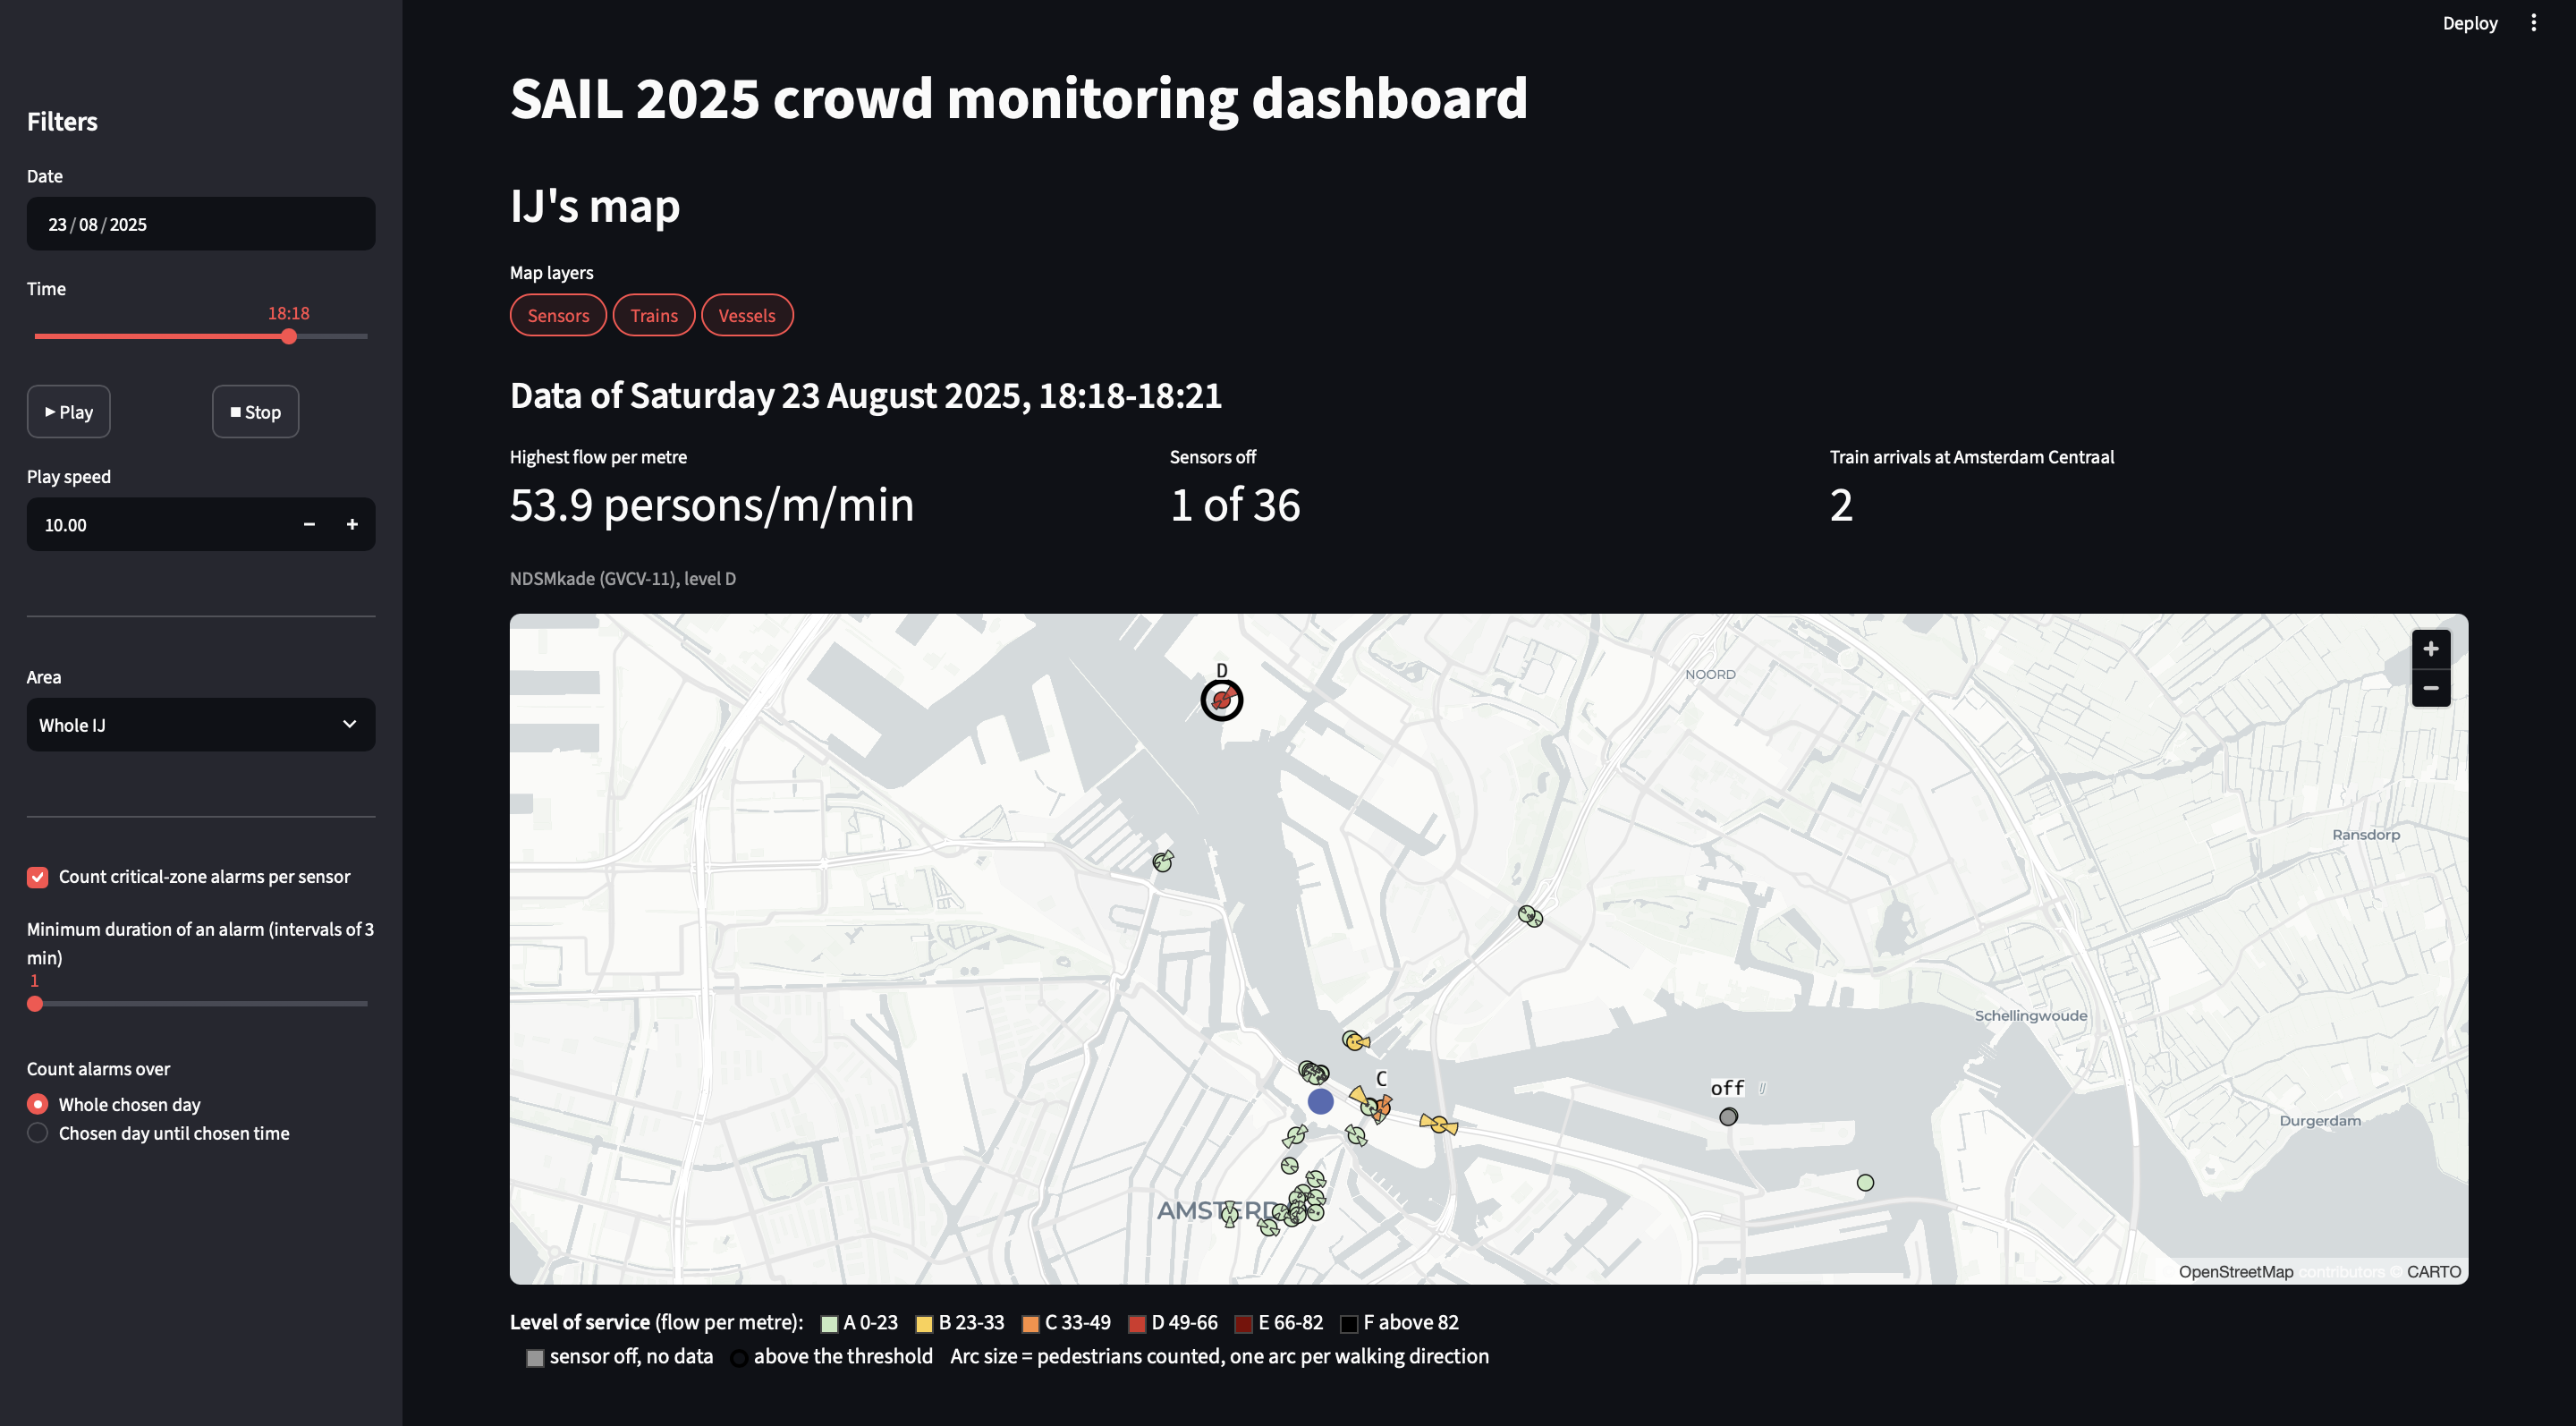

Side and top bar functionalities:

Map layer buttons:

    Sensors:

    Trains:

    Vessels:

Date selector:
Allows the operator to choose any single day from the 20th to the 24th of August, recalculating data for each sesor in the area.

Time slider:
Allows the operator to select a 3 minute range period for all the 24 hours of the day selected in the date selector, dragging the slider updates map overlays for that specific time window.

Playback buttons:
Automatating the time slider replay and allowing the operator 

Speed button:

Area filter dropdown:

Sensors, Trains and Vessels layers:



Map canvas:

Map navigation controls:

Bidirectional arc size:

Black critical circle:
above the critical threshold

Offline sensor markers:

Map legend:





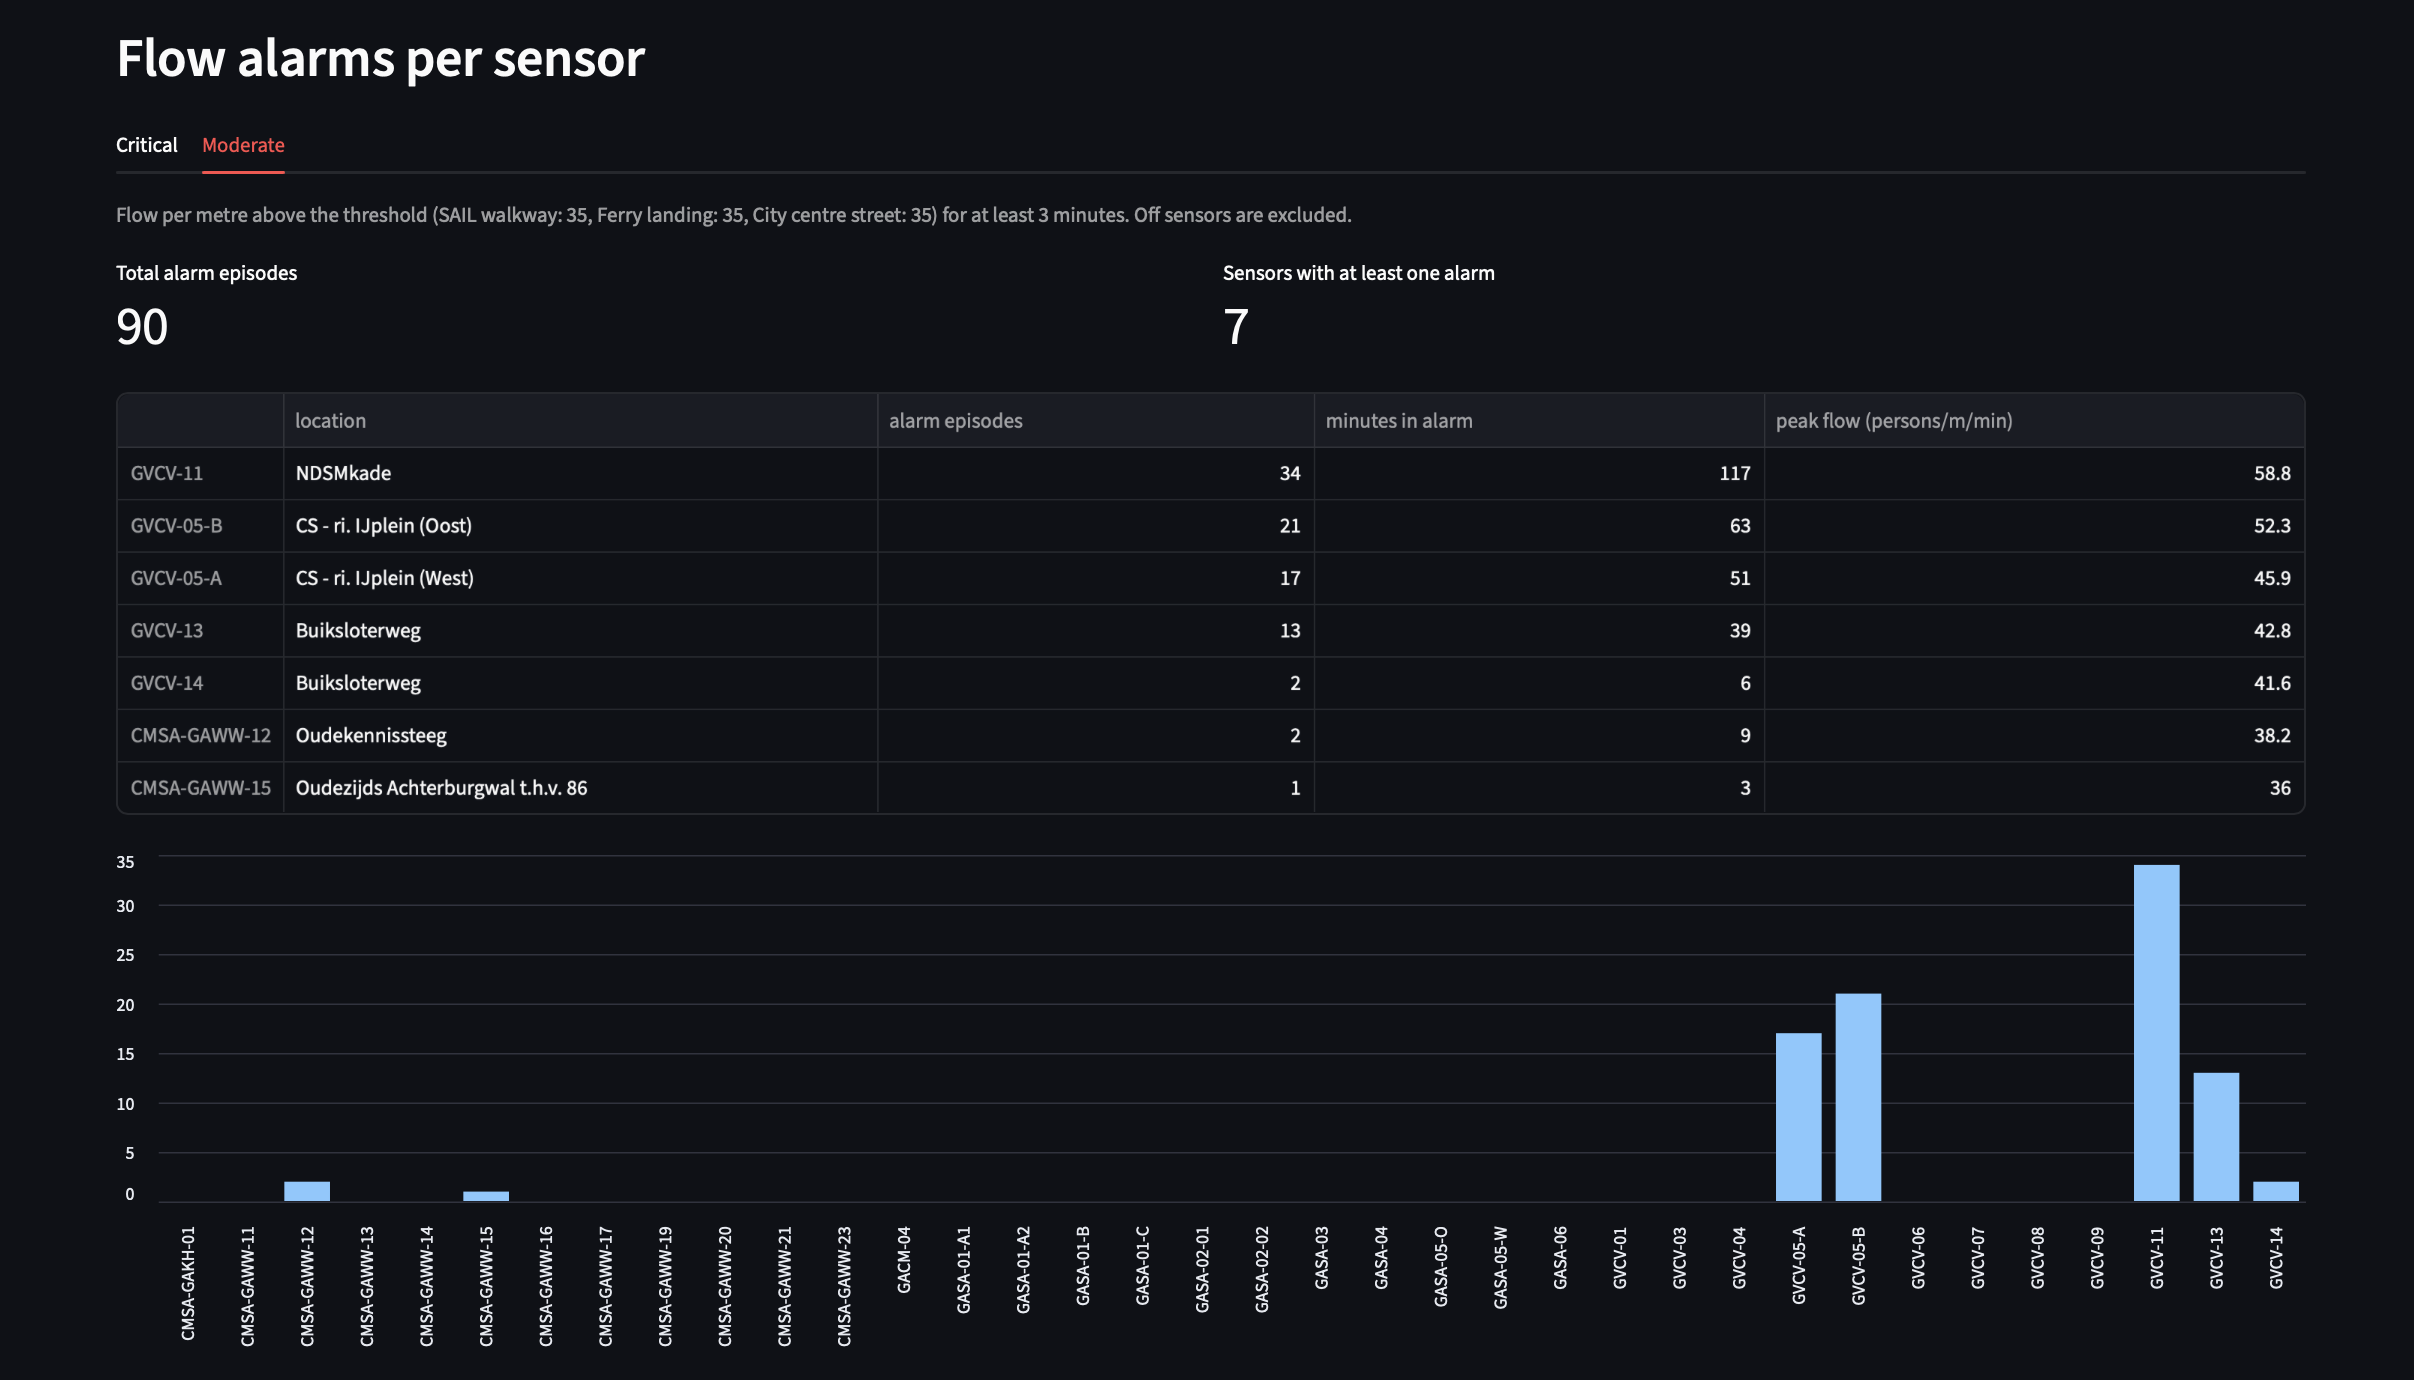

Flow Alarms per Sensor Section Analysis

This section of the dashoard collect the data about sensors which pass the threshold 49 for the critical and 35 or moderate allarms, the main functionalities are:

Filter (Critical / Moderate):

KPI:

    Number of total alarm episodes

    Number of the sensors which registered at least one alarm

    Name of the sensor which registered at least an alarm

    Location of the sensor which registered at least one alarm

    Number of episodes per sensor which registered at least one alarm

    Highest peak flow per sensor which registered at least one alarm



     




# SQ1 – Can we trust the sensors?

# SQ2 – Where and when was it busiest?

# SQ3 – Do SAIL events explain the peaks?

# SQ4 – Do trains explain the peaks?

Visitors who come to SAIL by train arrive at Amsterdam Centraal. If trains drive the counts, the sensors around the station should get busier a few minutes after each arrival. We looked at the 13 sensors within about 400 m of the station: four on the IJboulevard behind it (GASA-01), five at the ferry landings (GVCV), one on Damrak in front of it (GACM-04) and three on the east side (GASA-02 and GASA-04). For each sensor we added up both walking directions and compared the count with the trains that arrived in the same 3 minutes.

Trains and pedestrians both follow the clock, which makes a plain comparison misleading. Over the full 24 hours, arrivals and counts have a Pearson correlation of 0.40, but only because both drop at night. During the day the number of trains hardly changes, while the counts more than triple:

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "src")   # the modules in src/ import each other by their short names
from station_sensors import station_counts
from trains import train_counts
from train_effect import HOURS, lagged_correlations, remove_daily_pattern

people = station_counts()                  # one column per sensor, NaN when the sensor was off
total = people.sum(axis=1, skipna=False)   # the 13 sensors together
trains = train_counts()                    # arrivals and departures at Amsterdam Centraal

print("Train arrivals, 20-24 August:", trains["arrivals"].sum())
print(f"Correlation over 24 hours, daily pattern not removed: {trains['arrivals'].corr(total):.2f}")

daytime = slice(HOURS[0], HOURS[1] - 1)
trains_per_hour = trains["arrivals"].groupby(trains.index.hour).sum().loc[daytime] / 5   # 5 days
counts_per_hour = total.groupby(total.index.hour).mean().loc[daytime] * 20               # 20 intervals per hour
print(f"Trains per hour, 09:00-22:00: {trains_per_hour.min():.0f} to {trains_per_hour.max():.0f}")
print(f"Counts per hour at the 13 sensors: {counts_per_hour.min():,.0f} at {counts_per_hour.idxmin()}:00, "
      f"{counts_per_hour.max():,.0f} at {counts_per_hour.idxmax()}:00")

Train arrivals, 20-24 August: 3844
Correlation over 24 hours, daily pattern not removed: 0.40
Trains per hour, 09:00-22:00: 38 to 44
Counts per hour at the 13 sensors: 10,471 at 9:00, 37,844 at 17:00


So the daily peak does not come from more trains. A train could still add a short peak of its own on top of the daily curve. To find such peaks, we subtracted from both series their average over the surrounding hour and kept only 09:00 to 22:00. We left out the intervals in which a sensor was off (see SQ1) instead of counting them as zero. Passengers need a few minutes to walk from the platform to a sensor, so we compared the trains with the pedestrians counted 0 to 21 minutes later.

Pedestrians 0-21 minutes before a departure: -0.10 to 0.11
Arrivals vs arrivals 9 minutes later: -0.33, 15 minutes later: 0.32


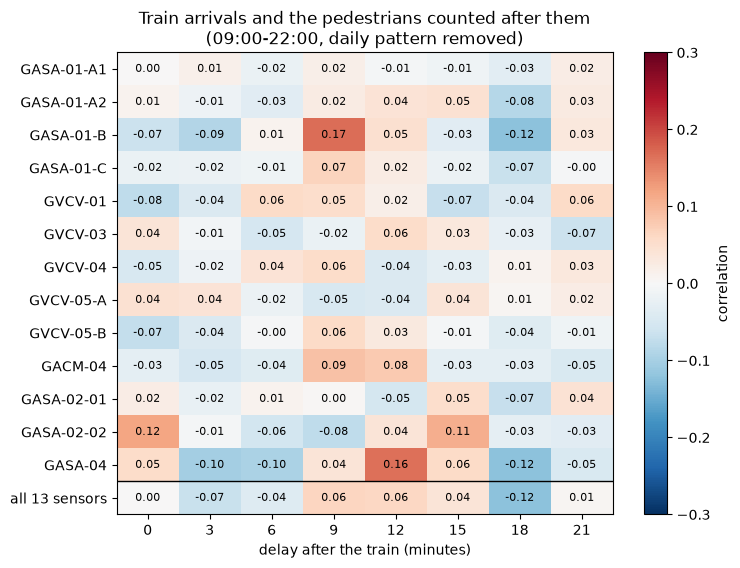

In [2]:
per_sensor = lagged_correlations(trains["arrivals"], people)
all_sensors = lagged_correlations(trains["arrivals"], total.to_frame("all 13 sensors"))
heat = pd.concat([per_sensor, all_sensors])

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(heat, cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        ax.text(col, row, f"{heat.iloc[row, col]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.axhline(len(per_sensor) - 0.5, color="black", linewidth=1)   # line between the sensors and their total
ax.set_xlabel("delay after the train (minutes)")
ax.set_title("Train arrivals and the pedestrians counted after them\n(09:00-22:00, daily pattern removed)")
fig.colorbar(image, ax=ax, label="correlation")

# people counted 0-21 minutes BEFORE a train departs: shift the counts forward instead of back
before = [lagged_correlations(trains["departures"], people.shift(k), max_lag=0).iloc[:, 0] for k in range(8)]
before = pd.concat(before, axis=1)
print(f"Pedestrians 0-21 minutes before a departure: {before.min().min():.2f} to {before.max().max():.2f}")
rhythm = remove_daily_pattern(trains["arrivals"])
print(f"Arrivals vs arrivals 9 minutes later: {rhythm.autocorr(3):.2f}, 15 minutes later: {rhythm.autocorr(5):.2f}")

Most of the heat map above is close to white. For the 13 sensors together, the correlation stays between -0.12 and 0.06 at every delay. Two sensors stand out a little: GASA-01-B on the IJboulevard, with 0.17 nine minutes after an arrival, and GASA-04 towards Oosterdokskade, with 0.16 after twelve minutes. Even these explain only about 3% of the variation (0.17² ≈ 0.03). The ferry landings stay between -0.08 and 0.06, and the counts before a departure show no link either (between -0.10 and 0.11). The blue cells around the red ones come from the timetable: trains at Amsterdam Centraal arrive in a rhythm of about 15 minutes, so an interval with many arrivals tends to be followed by a quieter one 9 minutes later (correlation -0.33).

The link is probably weak because during the day a train arrives about every one and a half minutes. The passengers of one train mix with those of the next, so the sensors see a steady stream instead of separate waves. We also count trains, not passengers, and a full train weighs as much as an empty one.

Our answer to SQ4 is therefore no: train arrivals do not explain the peaks near Amsterdam Centraal, at least not in a way the counts can show. The daily peak happens while the number of trains stays the same, and a single arrival has at most a small effect at two sensors. For the crowd manager, a sudden rise at the station sensors should not be read as a train that has just emptied, and the train layer of the dashboard gives context but no warning. A sharper test would need the number of passengers per train, which we did not have.

# SQ5 – Do vessels explain the peaks?

# Dashboard analysis

# Conclusion

# Discussion

# References

- Helbing, D., & Mukerji, P. (2012). Crowd disasters as systemic failures: analysis of the Love Parade disaster. *EPJ Data Science*, 1(7).
- Sharma, A., McCloskey, B., Hui, D. S., et al. (2023). Global mass gathering events and deaths due to crowd surge, stampedes, crush and physical injuries – lessons from the Seoul Halloween and other disasters. *Travel Medicine and Infectious Disease*, 52, 102524.
- Daamen, W. (2026). SAIL2025 Design Challenges. Lecture slides, TIL4030 Research and Design Methods, TU Delft.
- Fruin, J. J. (1971). *Pedestrian planning and design*. Metropolitan Association of Urban Designers and Environmental Planners.
- Rijden de Treinen. Open train archive, https://www.rijdendetreinen.nl/en/open-data/train-archive
- SAIL Amsterdam Foundation (2025). SAIL Amsterdam 2025, programme and event locations, https://www.sail.nl

# Use of AI